# Assignment 5 — Task 1: Bidirectional Transformer Encoder (AG News)

Implements the Task 1 requirements from the assignment PDF: balanced 20,000-row training subset, vocabulary 10,000–20,000, `[PAD]`/`[UNK]`/`[CLS]`, sequence length 64, bidirectional attention with padding mask, manual multi-head attention, encoder classification using `[CLS]`, and comparison of all 16 combinations of layers (2/4), heads (2/4), `d_model` (64/128), and positional encoding (learned/sinusoidal).

**Outputs:** architecture and epoch logs, training-loss plot for all configurations, validation/test metric tables, test Accuracy and Macro F1, best-model 4×4 confusion matrix, classification report, and `[CLS]` attention heatmaps across heads.

Upload `train.csv` and `test.csv` to Colab before running. The 20,000 balanced examples are split into 18,000 training and 2,000 validation examples; the official test file remains held out.

## 1. Imports, reproducibility, and device

In [ ]:
import os, re, math, time, copy, random, warnings
from collections import Counter
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
if DEVICE.type == "cuda": print("GPU:", torch.cuda.get_device_name(0))
else: print("WARNING: CPU detected; 16 experiments may take a long time.")

PyTorch: 2.14.1+cu130
Device: cuda
GPU: Tesla T4


## 2. Load AG News CSV files
Supports common header names (`Class Index`, `Title`, `Description`) and headerless three-column CSV files.

In [ ]:
TRAIN_PATH = "/content/train.csv"
TEST_PATH = "/content/test.csv"

def load_ag_news_csv(path):
    if not os.path.exists(path):
        raise FileNotFoundError(f"{path} not found. Upload the CSV to Colab or change the path.")
    df = pd.read_csv(path)
    cols = {str(c).strip().lower(): c for c in df.columns}
    label = next((cols[k] for k in cols if k in ["class index","class_index","label","class"]), None)
    title = cols.get("title")
    desc = next((cols[k] for k in cols if k in ["description","desc","text"]), None)
    if label is None or title is None:
        df = pd.read_csv(path, header=None)
        if df.shape[1] < 3: raise ValueError("CSV must have label, title, description columns.")
        df = df.iloc[:, :3].copy(); df.columns = ["label","title","description"]
        label, title, desc = "label","title","description"
    if desc is None:
        df["description"] = ""; desc = "description"
    out = pd.DataFrame({
        "label": pd.to_numeric(df[label], errors="coerce"),
        "title": df[title].fillna("").astype(str),
        "description": df[desc].fillna("").astype(str)
    }).dropna(subset=["label"])
    out["label"] = out["label"].astype(int)
    out = out[out.label.isin([1,2,3,4])].copy()
    out["text"] = (out.title.str.strip() + " " + out.description.str.strip()).str.strip()
    out["label"] = out["label"] - 1
    return out[["text","label"]].reset_index(drop=True)

train_df = load_ag_news_csv(TRAIN_PATH)
test_df = load_ag_news_csv(TEST_PATH)
CLASS_NAMES = ["World","Sports","Business","Sci/Tech"]
print("Train rows:", len(train_df), "| Test rows:", len(test_df))
print("Train class counts:\n", train_df.label.map(dict(enumerate(CLASS_NAMES))).value_counts())
print("Test class counts:\n", test_df.label.map(dict(enumerate(CLASS_NAMES))).value_counts())

Train rows: 120000 | Test rows: 7600
Train class counts:
 label
Business    30000
Sci/Tech    30000
Sports      30000
World       30000
Name: count, dtype: int64
Test class counts:
 label
Business    1900
Sci/Tech    1900
Sports      1900
World       1900
Name: count, dtype: int64


## 3. Balanced 20,000-row subset and validation split
Select 5,000 examples per class. Reserve 10% of this subset for validation. The official test split is not used for training/model selection.

In [ ]:
SAMPLES_PER_CLASS = 5000
balanced = pd.concat([
    train_df[train_df.label == c].sample(n=SAMPLES_PER_CLASS, random_state=SEED)
    for c in range(4)
]).sample(frac=1, random_state=SEED).reset_index(drop=True)

train_part, val_part = train_test_split(
    balanced, test_size=0.10, random_state=SEED, stratify=balanced.label
)
train_part = train_part.reset_index(drop=True)
val_part = val_part.reset_index(drop=True)
print("Balanced subset:", len(balanced))
print("Training:", len(train_part), "| Validation:", len(val_part), "| Official test:", len(test_df))
print("Training counts:\n", train_part.label.value_counts().sort_index())
print("Validation counts:\n", val_part.label.value_counts().sort_index())

Balanced subset: 20000
Training: 18000 | Validation: 2000 | Official test: 7600
Training counts:
 label
0    4500
1    4500
2    4500
3    4500
Name: count, dtype: int64
Validation counts:
 label
0    500
1    500
2    500
3    500
Name: count, dtype: int64


## 4. Tokenization and vocabulary
Word-level tokenization. Vocabulary is built from training text only, capped at 15,000 including the three required special tokens. Every sequence starts with `[CLS]` and is padded/truncated to 64.

In [ ]:
PAD, UNK, CLS = "[PAD]", "[UNK]", "[CLS]"
VOCAB_SIZE, MAX_SEQ_LEN = 15000, 64

def tokenize(text):
    return re.findall(r"[a-z0-9]+|[^\w\s]", str(text).lower())

counter = Counter()
for text in train_part.text: counter.update(tokenize(text))
vocab = {PAD:0, UNK:1, CLS:2}
for token, _ in counter.most_common(VOCAB_SIZE - 3):
    if token not in vocab: vocab[token] = len(vocab)

PAD_ID, UNK_ID, CLS_ID = vocab[PAD], vocab[UNK], vocab[CLS]
assert 10000 <= len(vocab) <= 20000, f"Vocabulary size {len(vocab)} outside required range."
def encode_text(text):
    ids = [CLS_ID] + [vocab.get(t, UNK_ID) for t in tokenize(text)]
    ids = ids[:MAX_SEQ_LEN]
    length = len(ids)
    ids += [PAD_ID] * (MAX_SEQ_LEN - length)
    return ids, length

print("Vocabulary size:", len(vocab))
print("Special token IDs:", {PAD:PAD_ID, UNK:UNK_ID, CLS:CLS_ID})
print("Max sequence length:", MAX_SEQ_LEN)
print("Example token IDs:", encode_text(train_part.text.iloc[0])[0][:20])

Vocabulary size: 15000
Special token IDs: {'[PAD]': 0, '[UNK]': 1, '[CLS]': 2}
Max sequence length: 64
Example token IDs: [2, 2222, 773, 9734, 1, 4819, 24, 4608, 1, 14, 8, 2103, 9, 763, 6, 1988, 1442, 12, 701, 14]


## 5. Dataset and DataLoaders
`key_padding_mask` is Boolean with shape `(batch, sequence_length)`: `True` means that position is padding and must not be attended to as a key.

In [ ]:
class NewsDataset(Dataset):
    def __init__(self, frame):
        self.texts = frame.text.tolist()
        self.labels = frame.label.astype(int).tolist()
    def __len__(self): return len(self.labels)
    def __getitem__(self, i):
        ids, length = encode_text(self.texts[i])
        ids = torch.tensor(ids, dtype=torch.long)
        mask = ids.eq(PAD_ID)  # True = padding
        return ids, mask, torch.tensor(self.labels[i], dtype=torch.long)

BATCH_SIZE = 128
train_loader = DataLoader(NewsDataset(train_part), batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(NewsDataset(val_part), batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(NewsDataset(test_df), batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
xb, mb, yb = next(iter(train_loader))
print("Input IDs:", tuple(xb.shape), "| Padding mask:", tuple(mb.shape), "| Labels:", tuple(yb.shape))
print("Mask sample (1=padding):", mb[0,:20].int().tolist())

Input IDs: (128, 64) | Padding mask: (128, 64) | Labels: (128,)
Mask sample (1=padding): [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


## 6. Positional encodings
Compare trainable learned positional embeddings with fixed sinusoidal encodings. Both are added to token embeddings.

In [ ]:
class PositionalEncoding(nn.Module):
    def __init__(self, max_len, d_model, mode):
        super().__init__()
        self.mode = mode
        if mode == "learned":
            self.embedding = nn.Embedding(max_len, d_model)
        elif mode == "sinusoidal":
            pos = torch.arange(max_len, dtype=torch.float32).unsqueeze(1)
            div = torch.exp(torch.arange(0,d_model,2,dtype=torch.float32) * (-math.log(10000.0)/d_model))
            pe = torch.zeros(max_len,d_model)
            pe[:,0::2] = torch.sin(pos*div)
            pe[:,1::2] = torch.cos(pos*div[:pe[:,1::2].shape[1]])
            self.register_buffer("pe", pe.unsqueeze(0))
        else: raise ValueError("mode must be learned or sinusoidal")
    def forward(self,x):
        if self.mode == "learned":
            p = torch.arange(x.size(1),device=x.device).unsqueeze(0)
            return x + self.embedding(p)
        return x + self.pe[:,:x.size(1),:]

## 7. Multi-Head Self-Attention from scratch
For each head, calculate Q, K, V projections, scaled dot-product attention, and concatenate heads. Task 1 is **bidirectional**: no causal triangular mask is applied. Only padding keys are masked.

In [ ]:
class MultiHeadSelfAttention(nn.Module):
    def __init__(self, d_model, heads, dropout=0.1):
        super().__init__()
        if d_model % heads: raise ValueError("d_model must be divisible by heads")
        self.d_model, self.heads = d_model, heads
        self.head_dim = d_model // heads
        self.q_proj = nn.Linear(d_model,d_model)
        self.k_proj = nn.Linear(d_model,d_model)
        self.v_proj = nn.Linear(d_model,d_model)
        self.out_proj = nn.Linear(d_model,d_model)
        self.dropout = nn.Dropout(dropout)
    def split_heads(self,x):
        b,s,_ = x.shape
        return x.view(b,s,self.heads,self.head_dim).transpose(1,2)
    def forward(self,x,key_padding_mask=None,return_attention=False):
        Q,K,V = self.split_heads(self.q_proj(x)), self.split_heads(self.k_proj(x)), self.split_heads(self.v_proj(x))
        scores = torch.matmul(Q,K.transpose(-2,-1)) / math.sqrt(self.head_dim)
        if key_padding_mask is not None:
            scores = scores.masked_fill(key_padding_mask[:,None,None,:], torch.finfo(scores.dtype).min)
        weights = torch.softmax(scores,dim=-1)
        context = torch.matmul(self.dropout(weights),V)
        context = context.transpose(1,2).contiguous().view(x.size(0),x.size(1),self.d_model)
        output = self.out_proj(context)
        return (output,weights) if return_attention else output

## 8. Encoder layer and `[CLS]` classifier
Each block uses attention, residual connection, LayerNorm, a GELU feed-forward network of width `4*d_model`, and a second residual/LayerNorm. The final `[CLS]` vector is classified into four categories.

In [ ]:
class EncoderLayer(nn.Module):
    def __init__(self,d_model,heads,dropout=0.1):
        super().__init__()
        self.attn = MultiHeadSelfAttention(d_model,heads,dropout)
        self.norm1, self.norm2 = nn.LayerNorm(d_model), nn.LayerNorm(d_model)
        self.drop1, self.drop2 = nn.Dropout(dropout), nn.Dropout(dropout)
        self.ffn = nn.Sequential(
            nn.Linear(d_model,4*d_model), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(4*d_model,d_model)
        )
    def forward(self,x,mask,return_attention=False):
        if return_attention: a,w = self.attn(x,mask,True)
        else: a = self.attn(x,mask)
        x = self.norm1(x + self.drop1(a))
        x = self.norm2(x + self.drop2(self.ffn(x)))
        return (x,w) if return_attention else x

class NewsTransformer(nn.Module):
    def __init__(self,vocab_size,max_len,d_model,heads,layers,positional,dropout=0.1):
        super().__init__()
        self.architecture = dict(layers=layers,heads=heads,d_model=d_model,
                                 positional=positional,max_len=max_len,ffn_dim=4*d_model)
        self.token_emb = nn.Embedding(vocab_size,d_model,padding_idx=PAD_ID)
        self.pos_emb = PositionalEncoding(max_len,d_model,positional)
        self.input_dropout = nn.Dropout(dropout)
        self.layers = nn.ModuleList([EncoderLayer(d_model,heads,dropout) for _ in range(layers)])
        self.classifier = nn.Linear(d_model,4)
    def forward(self,ids,pad_mask,return_attention=False):
        x = self.input_dropout(self.pos_emb(self.token_emb(ids)))
        attentions = []
        for layer in self.layers:
            if return_attention:
                x,w = layer(x,pad_mask,True); attentions.append(w)
            else: x = layer(x,pad_mask)
        logits = self.classifier(x[:,0,:])  # final [CLS] representation
        return (logits,attentions) if return_attention else logits

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

## 9. Training/evaluation functions and convergence rule
The assignment's stopping condition is checked using the absolute difference between successive average training losses. The best checkpoint is retained according to validation Macro F1. `MAX_EPOCHS` is a user-set upper limit because the PDF does not specify a fixed epoch count.

In [ ]:
MAX_EPOCHS = 10
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4
DROPOUT = 0.1
CONVERGENCE_TOL = 1e-4
GRAD_CLIP = 1.0

def run_epoch(model,loader,optimizer=None):
    training = optimizer is not None
    model.train() if training else model.eval()
    total_loss, total_n = 0.0, 0
    ys, preds = [], []
    with (torch.enable_grad() if training else torch.no_grad()):
        for ids,mask,y in loader:
            ids,mask,y = ids.to(DEVICE),mask.to(DEVICE),y.to(DEVICE)
            if training: optimizer.zero_grad(set_to_none=True)
            logits = model(ids,mask)
            loss = F.cross_entropy(logits,y)
            if training:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(),GRAD_CLIP)
                optimizer.step()
            n = y.size(0); total_loss += loss.item()*n; total_n += n
            ys.extend(y.detach().cpu().tolist())
            preds.extend(logits.argmax(1).detach().cpu().tolist())
    return total_loss/total_n, accuracy_score(ys,preds), f1_score(ys,preds,average="macro")

def train_configuration(cfg,number,total):
    model = NewsTransformer(len(vocab),MAX_SEQ_LEN,cfg["d_model"],cfg["heads"],
                            cfg["layers"],cfg["positional"],DROPOUT).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(),lr=LEARNING_RATE,weight_decay=WEIGHT_DECAY)
    desc = f'L={cfg["layers"]}, heads={cfg["heads"]}, d_model={cfg["d_model"]}, positional={cfg["positional"]}'
    print("\n"+"="*85)
    print(f"CONFIGURATION {number}/{total}: {desc}")
    print("Trainable parameters:",f"{count_parameters(model):,}")
    print(f"Batch={BATCH_SIZE}, max_epochs={MAX_EPOCHS}, lr={LEARNING_RATE}, dropout={DROPOUT}")
    print("="*85)
    history, previous_loss = [], None
    best_f1, best_state, best_epoch = -1, None, None
    start = time.time()
    for epoch in range(1,MAX_EPOCHS+1):
        t0 = time.time()
        tr_loss,tr_acc,tr_f1 = run_epoch(model,train_loader,optimizer)
        va_loss,va_acc,va_f1 = run_epoch(model,val_loader)
        delta = None if previous_loss is None else abs(tr_loss-previous_loss)
        elapsed = time.time()-t0
        history.append(dict(epoch=epoch,train_loss=tr_loss,train_accuracy=tr_acc,
                            train_macro_f1=tr_f1,val_loss=va_loss,val_accuracy=va_acc,
                            val_macro_f1=va_f1,loss_difference=delta,epoch_time_sec=elapsed))
        print(f"Epoch {epoch:02d}/{MAX_EPOCHS} | train_loss={tr_loss:.6f} | "
              f"train_acc={tr_acc:.4f} | val_loss={va_loss:.6f} | val_acc={va_acc:.4f} | "
              f"val_macro_F1={va_f1:.4f} | abs_loss_diff="
              f"{'N/A' if delta is None else f'{delta:.8f}'} | time={elapsed:.1f}s")
        if va_f1 > best_f1:
            best_f1, best_state, best_epoch = va_f1, copy.deepcopy(model.state_dict()), epoch
        if delta is not None and delta < CONVERGENCE_TOL:
            print(f"STOP: |L_epoch - L_previous|={delta:.8f} < {CONVERGENCE_TOL}")
            break
        previous_loss = tr_loss
    total_time = time.time()-start
    model.load_state_dict(best_state)
    print(f"FINISHED: {desc} | epochs_completed={len(history)} | best_val_epoch={best_epoch} | total_time={total_time:.1f}s")
    return model,history,total_time,best_epoch

## 10. Run the 16 required configurations
Set `RUN_ALL_CONFIGS=False` only for a quick code test. For the final assignment, use `True`. All 16 configurations may take substantial time, especially without a GPU.

In [ ]:
CONFIGURATIONS = [
    dict(layers=L,heads=H,d_model=D,positional=P)
    for L,H,D,P in product([2,4],[2,4],[64,128],["learned","sinusoidal"])
]
RUN_ALL_CONFIGS = True
configs_to_run = CONFIGURATIONS if RUN_ALL_CONFIGS else [CONFIGURATIONS[0]]

experiment_results, trained_models = [], {}
for i,cfg in enumerate(configs_to_run,1):
    model,hist,total_time,best_epoch = train_configuration(cfg,i,len(configs_to_run))
    key = f'L{cfg["layers"]}_H{cfg["heads"]}_D{cfg["d_model"]}_{cfg["positional"]}'
    trained_models[key] = model
    experiment_results.append(dict(model_key=key,config=cfg.copy(),history=hist,
                                   training_time_sec=total_time,best_epoch=best_epoch,
                                   epochs_completed=len(hist),
                                   best_val_macro_f1=max(r["val_macro_f1"] for r in hist)))
    if DEVICE.type == "cuda": torch.cuda.empty_cache()
print("\nTotal completed configurations:",len(experiment_results))


CONFIGURATION 1/16: L=2, heads=2, d_model=64, positional=learned
Trainable parameters: 1,064,324
Batch=128, max_epochs=10, lr=0.0003, dropout=0.1
Epoch 01/10 | train_loss=1.355069 | train_acc=0.3235 | val_loss=1.210748 | val_acc=0.4755 | val_macro_F1=0.4699 | abs_loss_diff=N/A | time=2.9s
Epoch 02/10 | train_loss=1.101299 | train_acc=0.5213 | val_loss=0.910760 | val_acc=0.6210 | val_macro_F1=0.6206 | abs_loss_diff=0.25377079 | time=2.1s
Epoch 03/10 | train_loss=0.920828 | train_acc=0.6236 | val_loss=0.777102 | val_acc=0.6900 | val_macro_F1=0.6893 | abs_loss_diff=0.18047048 | time=2.6s
Epoch 04/10 | train_loss=0.811954 | train_acc=0.6769 | val_loss=0.701278 | val_acc=0.7365 | val_macro_F1=0.7350 | abs_loss_diff=0.10887400 | time=6.3s
Epoch 05/10 | train_loss=0.723426 | train_acc=0.7210 | val_loss=0.632921 | val_acc=0.7650 | val_macro_F1=0.7642 | abs_loss_diff=0.08852847 | time=3.3s
Epoch 06/10 | train_loss=0.665118 | train_acc=0.7459 | val_loss=0.612203 | val_acc=0.7740 | val_macro_F1=

## 11. Training-loss curves for all configurations (required plot)

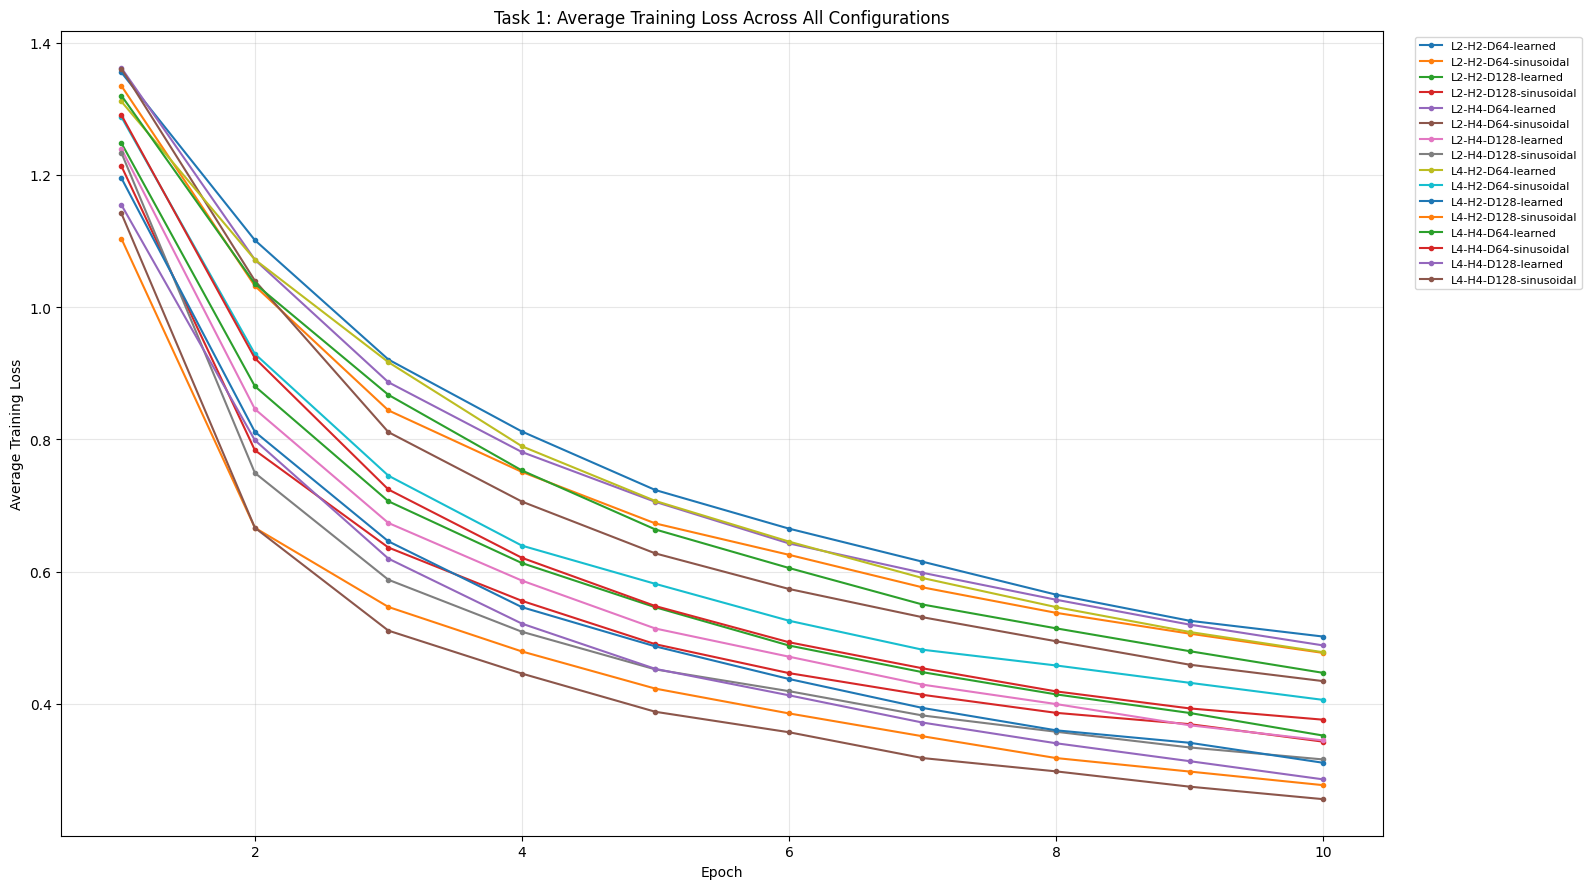

In [ ]:
plt.figure(figsize=(16,9))
for r in experiment_results:
    h = r["history"]; c = r["config"]
    label = f'L{c["layers"]}-H{c["heads"]}-D{c["d_model"]}-{c["positional"]}'
    plt.plot([z["epoch"] for z in h],[z["train_loss"] for z in h],
             marker="o",markersize=3,label=label)
plt.xlabel("Epoch"); plt.ylabel("Average Training Loss")
plt.title("Task 1: Average Training Loss Across All Configurations")
plt.grid(alpha=0.3); plt.legend(bbox_to_anchor=(1.02,1),loc="upper left",fontsize=8)
plt.tight_layout(); plt.show()

## 12. Epoch-wise logs and validation summary
These outputs explicitly show each architecture, number of epochs completed, best epoch, validation metrics, and runtime.

In [ ]:
epoch_rows, summary_rows = [], []
for r in experiment_results:
    c, key = r["config"], r["model_key"]
    for z in r["history"]:
        epoch_rows.append({"Model":key,"Layers":c["layers"],"Heads":c["heads"],
                           "d_model":c["d_model"],"Positional":c["positional"],**z})
    best = max(r["history"],key=lambda z:z["val_macro_f1"])
    summary_rows.append({"Model":key,"Layers":c["layers"],"Heads":c["heads"],
                         "d_model":c["d_model"],"Positional":c["positional"],
                         "Epochs Completed":r["epochs_completed"],"Best Epoch":r["best_epoch"],
                         "Best Val Accuracy":best["val_accuracy"],
                         "Best Val Macro F1":best["val_macro_f1"],
                         "Final Train Loss":r["history"][-1]["train_loss"],
                         "Training Time (sec)":r["training_time_sec"]})
epoch_log_df = pd.DataFrame(epoch_rows)
validation_summary_df = pd.DataFrame(summary_rows).sort_values(
    "Best Val Macro F1",ascending=False).reset_index(drop=True)
print("Epoch-wise log (first 40 rows):"); display(epoch_log_df.head(40))
print("Validation summary — all configurations:"); display(validation_summary_df)

Epoch-wise log (first 40 rows):


,Model,Layers,Heads,d_model,Positional,epoch,train_loss,train_accuracy,train_macro_f1,val_loss,val_accuracy,val_macro_f1,loss_difference,epoch_time_sec
0,L2_H2_D64_learned,2,2,64,learned,1,1.355069,0.323500,0.323344,1.210748,0.4755,0.469935,NaN,2.893782
1,L2_H2_D64_learned,2,2,64,learned,2,1.101299,0.521278,0.519069,0.910760,0.6210,0.620625,0.253771,2.114477
2,L2_H2_D64_learned,2,2,64,learned,3,0.920828,0.623556,0.622106,0.777102,0.6900,0.689339,0.180470,2.609583
3,L2_H2_D64_learned,2,2,64,learned,4,0.811954,0.676889,0.676093,0.701278,0.7365,0.735043,0.108874,6.270326
4,L2_H2_D64_learned,2,2,64,learned,5,0.723426,0.721000,0.720291,0.632921,0.7650,0.764166,0.088528,3.291705
5,L2_H2_D64_learned,2,2,64,learned,6,0.665118,0.745944,0.745527,0.612203,0.7740,0.772648,0.058307,2.130691
6,L2_H2_D64_learned,2,2,64,learned,7,0.615116,0.771611,0.771150,0.574441,0.7880,0.787563,0.050003,3.072209
7,L2_H2_D64_learned,2,2,64,learned,8,0.565325,0.790167,0.789654,0.539296,0.8100,0.809609,0.049790,2.064543
8,L2_H2_D64_learned,2,2,64,learned,9,0.525827,0.806778,0.806368,0.541799,0.8065,0.804996,0.039498,2.166754
9,L2_H2_D64_learned,2,2,64,learned,10,0.501921,0.816222,0.815736,0.509632,0.8250,0.824564,0.023906,2.082732


Validation summary — all configurations:


,Model,Layers,Heads,d_model,Positional,Epochs Completed,Best Epoch,Best Val Accuracy,Best Val Macro F1,Final Train Loss,Training Time (sec)
0,L4_H2_D128_sinusoidal,4,2,128,sinusoidal,10,10,0.8725,0.871783,0.277201,47.710746
1,L4_H4_D128_sinusoidal,4,4,128,sinusoidal,10,9,0.8670,0.867483,0.256025,51.516909
2,L2_H4_D128_sinusoidal,2,4,128,sinusoidal,10,10,0.8620,0.861910,0.316087,31.073374
3,L2_H2_D128_sinusoidal,2,2,128,sinusoidal,10,10,0.8580,0.858132,0.342991,29.901578
4,L4_H2_D128_learned,4,2,128,learned,10,10,0.8580,0.857485,0.311058,48.116096
5,L4_H4_D128_learned,4,4,128,learned,10,9,0.8570,0.856666,0.285966,51.610256
6,L4_H4_D64_sinusoidal,4,4,64,sinusoidal,10,9,0.8555,0.855820,0.376187,34.326174
7,L2_H4_D128_learned,2,4,128,learned,10,10,0.8525,0.852216,0.344846,30.720102
8,L2_H2_D128_learned,2,2,128,learned,10,10,0.8490,0.848361,0.352238,28.633683
9,L4_H2_D64_sinusoidal,4,2,64,sinusoidal,10,10,0.8470,0.846077,0.406160,33.244414


## 13. Official test metrics for all configurations
The best architecture is selected using validation Macro F1. Test Accuracy and Macro F1 are then reported for every trained configuration.

In [ ]:
def predict_model(model,loader):
    model.eval(); ys,preds = [],[]
    with torch.no_grad():
        for ids,mask,y in loader:
            logits = model(ids.to(DEVICE),mask.to(DEVICE))
            ys.extend(y.tolist()); preds.extend(logits.argmax(1).cpu().tolist())
    return np.array(ys),np.array(preds)

test_rows, test_predictions = [], {}
for r in experiment_results:
    key,c = r["model_key"],r["config"]
    yt,yp = predict_model(trained_models[key],test_loader)
    test_predictions[key] = (yt,yp)
    test_rows.append({"Model":key,"Layers":c["layers"],"Heads":c["heads"],
                      "d_model":c["d_model"],"Positional":c["positional"],
                      "Epochs":r["epochs_completed"],
                      "Test Accuracy":accuracy_score(yt,yp),
                      "Test Macro F1":f1_score(yt,yp,average="macro"),
                      "Training Time (sec)":r["training_time_sec"]})
test_results_df = pd.DataFrame(test_rows).sort_values(
    "Test Macro F1",ascending=False).reset_index(drop=True)
print("Required test summary table:"); display(test_results_df)

best_result = max(experiment_results,key=lambda r:r["best_val_macro_f1"])
best_model_key = best_result["model_key"]
best_model = trained_models[best_model_key]
best_y_true,best_y_pred = test_predictions[best_model_key]
print("\nBEST MODEL (selected using validation Macro F1)")
print("Architecture:",best_result["config"])
print("Model key:",best_model_key)
print("Trainable parameters:",f"{count_parameters(best_model):,}")
print("Best epoch:",best_result["best_epoch"])
print("Epochs completed:",best_result["epochs_completed"])
print("Test Accuracy:",f"{accuracy_score(best_y_true,best_y_pred):.4f}")
print("Test Macro F1:",f"{f1_score(best_y_true,best_y_pred,average='macro'):.4f}")

Required test summary table:


,Model,Layers,Heads,d_model,Positional,Epochs,Test Accuracy,Test Macro F1,Training Time (sec)
0,L4_H2_D128_sinusoidal,4,2,128,sinusoidal,10,0.870658,0.870219,47.710746
1,L4_H4_D128_sinusoidal,4,4,128,sinusoidal,10,0.868289,0.868416,51.516909
2,L2_H4_D128_sinusoidal,2,4,128,sinusoidal,10,0.860395,0.859986,31.073374
3,L2_H2_D128_sinusoidal,2,2,128,sinusoidal,10,0.857632,0.858170,29.901578
4,L4_H4_D128_learned,4,4,128,learned,10,0.855395,0.855147,51.610256
5,L4_H2_D64_sinusoidal,4,2,64,sinusoidal,10,0.850789,0.850074,33.244414
6,L4_H2_D128_learned,4,2,128,learned,10,0.850526,0.850036,48.116096
7,L4_H4_D64_sinusoidal,4,4,64,sinusoidal,10,0.849342,0.849455,34.326174
8,L2_H2_D128_learned,2,2,128,learned,10,0.848289,0.847617,28.633683
9,L2_H4_D128_learned,2,4,128,learned,10,0.845921,0.845462,30.720102



BEST MODEL (selected using validation Macro F1)
Architecture: {'layers': 4, 'heads': 2, 'd_model': 128, 'positional': 'sinusoidal'}
Model key: L4_H2_D128_sinusoidal
Trainable parameters: 2,713,604
Best epoch: 10
Epochs completed: 10
Test Accuracy: 0.8707
Test Macro F1: 0.8702


## 14. Best-model 4×4 confusion matrix and classification report (required)

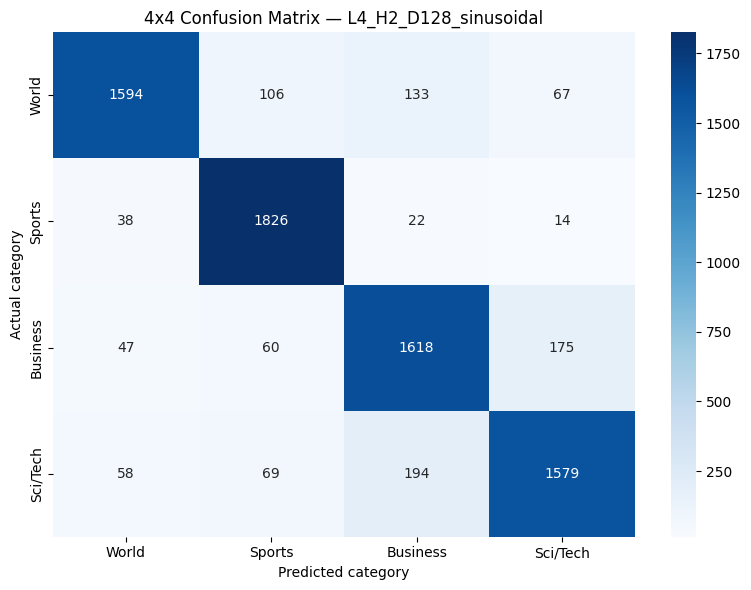

              precision    recall  f1-score   support

       World     0.9177    0.8389    0.8765      1900
      Sports     0.8860    0.9611    0.9220      1900
    Business     0.8226    0.8516    0.8368      1900
    Sci/Tech     0.8605    0.8311    0.8455      1900

    accuracy                         0.8707      7600
   macro avg     0.8717    0.8707    0.8702      7600
weighted avg     0.8717    0.8707    0.8702      7600



In [ ]:
cm = confusion_matrix(best_y_true,best_y_pred,labels=[0,1,2,3])
plt.figure(figsize=(8,6))
sns.heatmap(cm,annot=True,fmt="d",cmap="Blues",
            xticklabels=CLASS_NAMES,yticklabels=CLASS_NAMES)
plt.xlabel("Predicted category"); plt.ylabel("Actual category")
plt.title(f"4x4 Confusion Matrix — {best_model_key}")
plt.tight_layout(); plt.show()
print(classification_report(best_y_true,best_y_pred,target_names=CLASS_NAMES,digits=4))

## 15. Bidirectional `[CLS]` attention heatmaps across heads (required)
For a correctly classified test example, visualize the final encoder layer's attention from the `[CLS]` query to each valid token. Padding is excluded. There is no triangular causal mask in this encoder task.

Text: Fears for T N pension after talks Unions representing workers at Turner   Newall say they are 'disappointed' after talks with stricken parent firm Federal Mogul.
Actual: Business | Predicted: Business
Architecture: {'layers': 4, 'heads': 2, 'd_model': 128, 'positional': 'sinusoidal'} | Visualized layer: last encoder layer


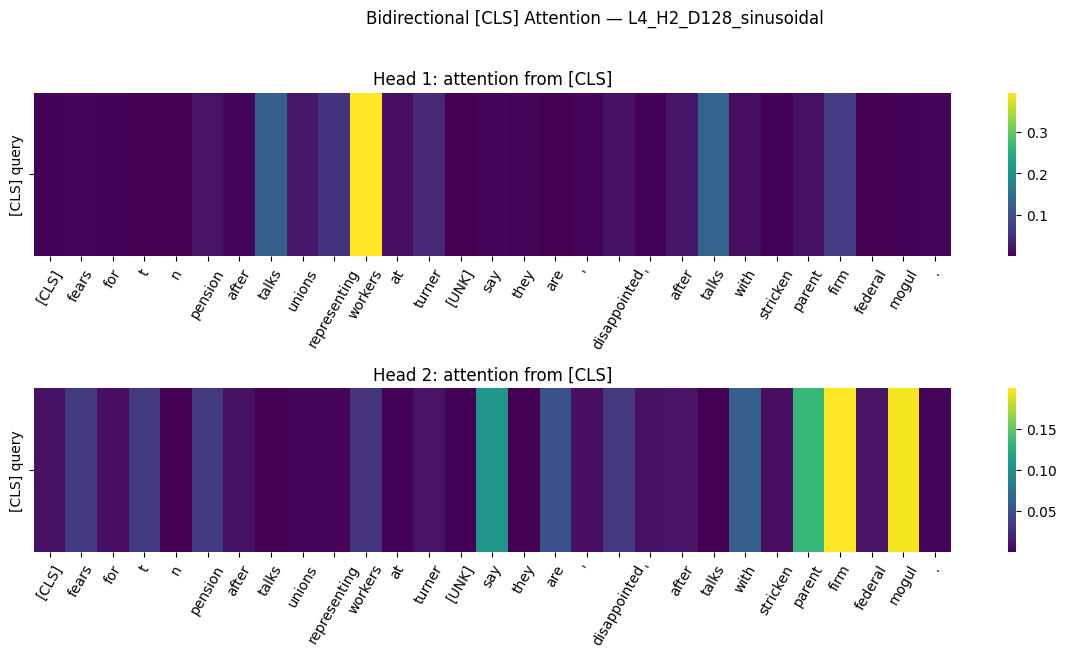

In [ ]:
correct = np.where(best_y_true==best_y_pred)[0]
sample_i = int(correct[0]) if len(correct) else 0
sample_text = test_df.text.iloc[sample_i]
sample_label = int(test_df.label.iloc[sample_i])
ids_list,length = encode_text(sample_text)
ids = torch.tensor([ids_list],dtype=torch.long,device=DEVICE)
mask = ids.eq(PAD_ID)
best_model.eval()
with torch.no_grad():
    logits,all_attn = best_model(ids,mask,return_attention=True)
predicted = int(logits.argmax(1).item())
# Last layer: (heads, query positions, key positions); query position zero is [CLS].
cls_weights = all_attn[-1][0,:,0,:length].cpu().numpy()
id_to_token = {i:t for t,i in vocab.items()}
tokens = [id_to_token.get(i,UNK) for i in ids_list[:length]]
print("Text:",sample_text[:400])
print("Actual:",CLASS_NAMES[sample_label],"| Predicted:",CLASS_NAMES[predicted])
print("Architecture:",best_result["config"],"| Visualized layer: last encoder layer")
fig,axes = plt.subplots(cls_weights.shape[0],1,
                        figsize=(max(12,length*0.35),3.2*cls_weights.shape[0]))
if cls_weights.shape[0]==1: axes=[axes]
for h,ax in enumerate(axes):
    sns.heatmap(cls_weights[h][None,:],ax=ax,cmap="viridis",
                xticklabels=tokens,yticklabels=["[CLS] query"],cbar=True)
    ax.set_title(f"Head {h+1}: attention from [CLS]")
    ax.tick_params(axis="x",rotation=60)
plt.suptitle(f"Bidirectional [CLS] Attention — {best_model_key}",y=1.02)
plt.tight_layout(); plt.show()

## 16. Empirical analysis: number of heads and depth
These grouped averages support the report discussion. Since multiple hyperparameters vary in the experiment, treat the group comparisons as empirical trends, not perfectly isolated causal effects.

Mean test scores grouped by attention heads:


,Heads,Test Accuracy,Test Macro F1
0,2,0.842286,0.841849
1,4,0.843651,0.843234


Mean test scores grouped by encoder depth:


,Layers,Test Accuracy,Test Macro F1
0,2,0.837796,0.837257
1,4,0.848141,0.847826


Mean training time grouped by depth:


,Layers,Training Time (sec)
0,2,27.365158
1,4,41.666013


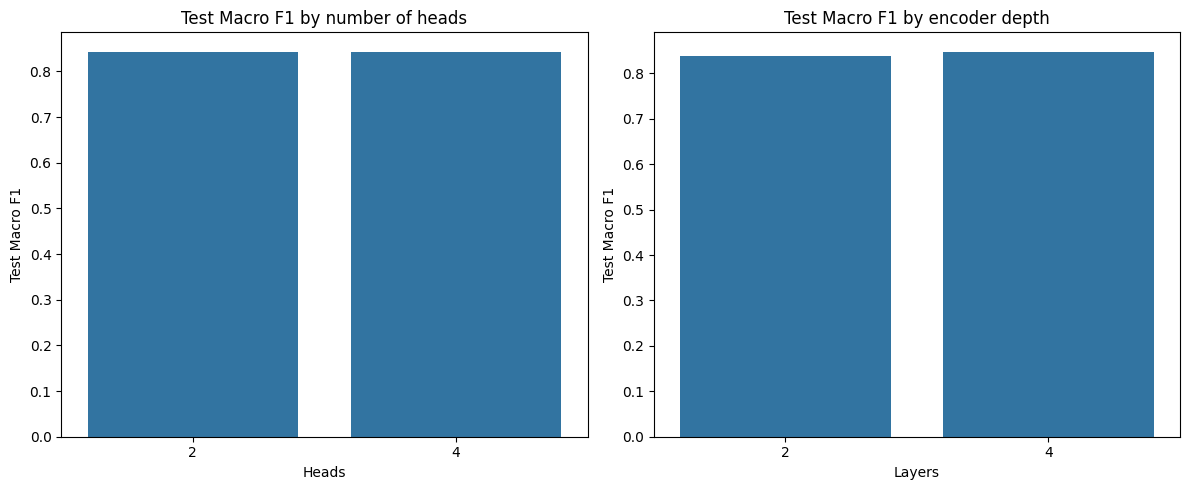

In [ ]:
print("Mean test scores grouped by attention heads:")
display(test_results_df.groupby("Heads")[["Test Accuracy","Test Macro F1"]].mean().reset_index())
print("Mean test scores grouped by encoder depth:")
display(test_results_df.groupby("Layers")[["Test Accuracy","Test Macro F1"]].mean().reset_index())
print("Mean training time grouped by depth:")
display(test_results_df.groupby("Layers")["Training Time (sec)"].mean().reset_index())
fig,axes = plt.subplots(1,2,figsize=(12,5))
sns.barplot(data=test_results_df,x="Heads",y="Test Macro F1",ax=axes[0],errorbar=None)
axes[0].set_title("Test Macro F1 by number of heads")
sns.barplot(data=test_results_df,x="Layers",y="Test Macro F1",ax=axes[1],errorbar=None)
axes[1].set_title("Test Macro F1 by encoder depth")
plt.tight_layout(); plt.show()

## 17. Save report tables and best model checkpoint

In [ ]:
OUTPUT_DIR = "/content/task1_outputs"
os.makedirs(OUTPUT_DIR,exist_ok=True)
epoch_log_df.to_csv(os.path.join(OUTPUT_DIR,"task1_epoch_wise_log.csv"),index=False)
validation_summary_df.to_csv(os.path.join(OUTPUT_DIR,"task1_validation_summary.csv"),index=False)
test_results_df.to_csv(os.path.join(OUTPUT_DIR,"task1_test_metrics_all_configurations.csv"),index=False)
torch.save({"model_key":best_model_key,"architecture":best_result["config"],
            "vocab":vocab,"state_dict":best_model.state_dict(),
            "class_names":CLASS_NAMES,"max_seq_len":MAX_SEQ_LEN},
           os.path.join(OUTPUT_DIR,"best_task1_transformer.pt"))
print("Saved outputs:")
for name in sorted(os.listdir(OUTPUT_DIR)): print("-",name)

Saved outputs:
- best_task1_transformer.pt
- task1_epoch_wise_log.csv
- task1_test_metrics_all_configurations.csv
- task1_validation_summary.csv


## 18. Report discussion checklist

Use the actual numbers produced by your run—do not invent results.

1. **Best architecture:** layers, heads, `d_model`, positional encoding, parameter count, best validation epoch, epochs completed, test Accuracy, and test Macro F1.
2. **Heads:** compare average results for 2 versus 4 heads. Multiple heads can learn different attention patterns, but more heads do not guarantee better performance and may increase computation.
3. **Depth:** compare 2 versus 4 layers. More layers may learn richer representations but require more compute and may overfit.
4. **Position encoding:** compare learned versus sinusoidal. Learned vectors adapt to the dataset; sinusoidal vectors are fixed and add no trainable position parameters.
5. **Confusion matrix:** identify category pairs that are most frequently confused.
6. **Attention:** describe tokens receiving high attention from `[CLS]`. Attention weights are diagnostic, not a complete explanation of model decisions.

**Limitations:** this is a compact word-level Transformer trained from scratch, not pretrained BERT. The optional bonus depth study (`L=6,8`) is not included in the 16 baseline configurations. Runtime depends on available hardware.

**Submission reminder from the PDF:** save the notebook as `code.ipynb`, keep all outputs visible, and include the plots/tables/inferences in `report.pdf`.